Ex1

Subpunctul d

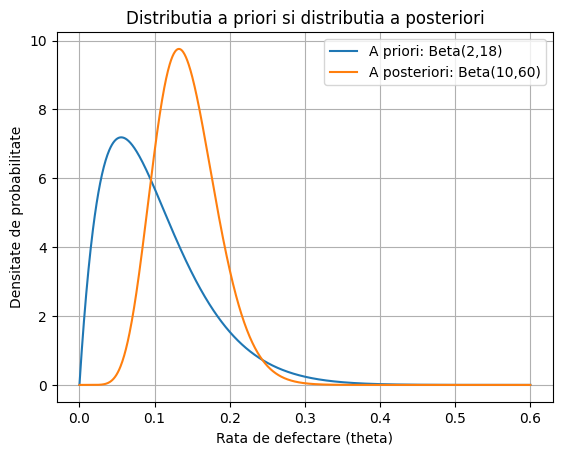

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

theta = np.linspace(0, 0.6, 1000)

prior = beta.pdf(theta, 2, 18)
posterior = beta.pdf(theta, 10, 60)

plt.plot(theta, prior, label="A priori: Beta(2,18)")
plt.plot(theta, posterior, label="A posteriori: Beta(10,60)")

plt.xlabel("Rata de defectare (theta)")
plt.ylabel("Densitate de probabilitate")
plt.title("Distributia a priori si distributia a posteriori")
plt.legend()
plt.grid()
plt.show()

Subpunctul e

In [2]:
from scipy.stats import beta

alpha = 10
beta_param = 60

limita_inf = beta.ppf(0.025, alpha, beta_param)
limita_sup = beta.ppf(0.975, alpha, beta_param)

print("Limita inferioara:", limita_inf)
print("Limita superioara:", limita_sup)

Limita inferioara: 0.07174913989206377
Limita superioara: 0.2332189597948612


Subpunctul f

In [3]:
from scipy.stats import beta

alpha = 10
beta_param = 60
probabilitate = beta.cdf(0.10, alpha, beta_param)

print(probabilitate * 100, "%")

14.837323361352764 %


Subpunctul g

In [4]:
from scipy.special import beta

P = beta(10, 70) / beta(10, 60)
print(P)

0.23602209274442953


Ex2

Subpunctul a

In [5]:

import numpy as np

lambda_sosiri = 20 / 60
media_plata = 2
alpha = 0

sosiri = []
timp = 0

while True:
    timp += np.random.exponential(scale=1 / lambda_sosiri)

    if timp > 60:
        break

    sosiri.append(timp)

N = len(sosiri)

timpi_plata = np.random.exponential(
    scale=media_plata, size=N
)

timpi_preparare = np.random.exponential(
    scale=alpha, size=N
)

inceput_plata = []
sfarsit_plata = []

for i in range(N):

    if i == 0:
        start = sosiri[i]
    else:
        start = max(sosiri[i], sfarsit_plata[i - 1])

    finish = start + timpi_plata[i]

    inceput_plata.append(start)
    sfarsit_plata.append(finish)

inceput_preparare = []
sfarsit_preparare = []

for i in range(N):

    if i == 0:
        start = sfarsit_plata[i]
    else:
        start = max(
            sfarsit_plata[i],
            sfarsit_preparare[i - 1]
        )

    finish = start + timpi_preparare[i]

    inceput_preparare.append(start)
    sfarsit_preparare.append(finish)

timp_total = np.array(sfarsit_preparare) - np.array(sosiri)

asteptare_plata = np.array(inceput_plata) - np.array(sosiri)

asteptare_gatit = (
    np.array(inceput_preparare) - np.array(sfarsit_plata)
)

asteptare_totala = asteptare_plata + asteptare_gatit


print("SIMULAREA RESTAURANTULUI FAST-FOOD")
print("-----------------------------------")

print("Numar clienti:", N)
print("Media timpului de preparare:", alpha, "minute")

print("\nDETALII PENTRU FIECARE CLIENT")
print("-" * 125)

print(
    f"{'Client':<8}"
    f"{'Sosire':>10}"
    f"{'Ajunge la casa':>17}"
    f"{'Plata':>10}"
    f"{'Final plata':>14}"
    f"{'Inceput gatit':>16}"
    f"{'Final gatit':>14}"
    f"{'Timp total':>14}"
)

for i in range(N):
    print(
        f"{i+1:<8}"
        f"{sosiri[i]:>10.2f}"
        f"{inceput_plata[i]:>17.2f}"
        f"{timpi_plata[i]:>10.2f}"
        f"{sfarsit_plata[i]:>14.2f}"
        f"{inceput_preparare[i]:>16.2f}"
        f"{sfarsit_preparare[i]:>14.2f}"
        f"{timp_total[i]:>14.2f}"
    )


SIMULAREA RESTAURANTULUI FAST-FOOD
-----------------------------------
Numar clienti: 22
Media timpului de preparare: 0 minute

DETALII PENTRU FIECARE CLIENT
-----------------------------------------------------------------------------------------------------------------------------
Client      Sosire   Ajunge la casa     Plata   Final plata   Inceput gatit   Final gatit    Timp total
1             1.89             1.89     10.98         12.87           12.87         12.87         10.98
2             3.72            12.87      0.47         13.34           13.34         13.34          9.61
3             8.26            13.34      0.89         14.23           14.23         14.23          5.97
4             9.34            14.23      2.23         16.45           16.45         16.45          7.11
5            11.45            16.45      1.31         17.77           17.77         17.77          6.31
6            13.35            17.77      1.59         19.36           19.36         19.36   

Subpunctul b

In [6]:
import numpy as np

def simuleaza_o_ora(alpha):

    sosiri = []
    timp = 0

    while True:
        timp += np.random.exponential(scale=3)

        if timp > 60:
            break

        sosiri.append(timp)

    N = len(sosiri)

    timpi_plata = np.random.exponential(scale=2, size=N)
    timpi_preparare = np.random.exponential(scale=alpha, size=N)

    sfarsit_plata = []

    for i in range(N):

        if i == 0:
            start = sosiri[i]
        else:
            start = max(sosiri[i], sfarsit_plata[i-1])

        finish = start + timpi_plata[i]
        sfarsit_plata.append(finish)

    sfarsit_preparare = []

    for i in range(N):

        if i == 0:
            start = sfarsit_plata[i]
        else:
            start = max(sfarsit_plata[i],
                        sfarsit_preparare[i-1])

        finish = start + timpi_preparare[i]
        sfarsit_preparare.append(finish)

    timp_total = np.array(sfarsit_preparare) - np.array(sosiri)

    return np.all(timp_total <= 15)




def estimeaza_probabilitatea(alpha, nr_simulari=10000):

    succese = 0

    for _ in range(nr_simulari):

        if simuleaza_o_ora(alpha):
            succese += 1

    return succese / nr_simulari




print("TESTAREA VALORILOR ALPHA")

for alpha in [1, 2, 2.5, 3, 4, 5]:

    p = estimeaza_probabilitatea(alpha)

    print(f"Alpha = {alpha:.2f} | "
          f"Probabilitate = {p*100:.2f}%")




stanga = 0
dreapta = 10
precizie = 0.0001

p_zero = estimeaza_probabilitatea(0, 200000)

print("Probabilitate pentru alpha = 0:",
      round(p_zero * 100, 2), "%")

if p_zero < 0.95:

    print("\nNu exista o valoare alpha care sa respecte conditia de 95%.")

else:

    while dreapta - stanga > precizie:

        mijloc = (stanga + dreapta) / 2

        p = estimeaza_probabilitatea(mijloc)

        print(f"Alpha = {mijloc:.4f} | P = {p*100:.2f}%")

        if p >= 0.95:
            stanga = mijloc
        else:
            dreapta = mijloc

    alpha_max = stanga

    print("\nREZULTAT FINAL")
    print("Alpha maxim:", round(alpha_max, 4))
    print("Probabilitate:",
          round(estimeaza_probabilitatea(alpha_max, 200000)*100, 2), "%")


TESTAREA VALORILOR ALPHA
Alpha = 1.00 | Probabilitate = 73.53%
Alpha = 2.00 | Probabilitate = 44.19%
Alpha = 2.50 | Probabilitate = 27.41%
Alpha = 3.00 | Probabilitate = 14.89%
Alpha = 4.00 | Probabilitate = 4.28%
Alpha = 5.00 | Probabilitate = 1.42%
Probabilitate pentru alpha = 0: 81.16 %

Nu exista o valoare alpha care sa respecte conditia de 95%.


Putem observa ca nu putem obtine o probabilitate de 95% nici macar pt alfa=0

Subpunctul c

In [7]:
import numpy as np

rng = np.random.default_rng(42)

alpha = 0
nr_simulari = 20000

toti_timpii = []

for _ in range(nr_simulari):

    N = rng.poisson(20)

    if N == 0:
        continue

    sosiri = np.sort(rng.uniform(0, 60, size=N))

    timpi_plata = rng.exponential(scale=2, size=N)

    timpi_preparare = np.zeros(N)

    sfarsit_plata = []
    sfarsit_preparare = []

    for i in range(N):

        if i == 0:
            start = sosiri[i]
        else:
            start = max(sosiri[i], sfarsit_plata[i-1])

        finish = start + timpi_plata[i]
        sfarsit_plata.append(finish)

    for i in range(N):

        if i == 0:
            start = sfarsit_plata[i]
        else:
            start = max(sfarsit_plata[i],
                        sfarsit_preparare[i-1])

        finish = start + timpi_preparare[i]
        sfarsit_preparare.append(finish)

    timp_total = np.array(sfarsit_preparare) - sosiri

    toti_timpii.extend(timp_total)

timp_mediu = np.mean(toti_timpii)

print("Numar total de clienti:", len(toti_timpii))
print("Timpul mediu petrecut in restaurant:",
      round(timp_mediu, 2), "minute")


Numar total de clienti: 399462
Timpul mediu petrecut in restaurant: 4.96 minute


Pentru estimarea probabilităților am utilizat 20.000 de simulări independente ale unei ore de funcționare a restaurantului. Pentru reproducerea rezultatelor se poate fixa o sămânță aleatoare, de exemplu 42, folosind generatorul de numere aleatoare din NumPy.

Pentru determinarea valorii maxime a lui α am avut în vedere metoda căutării binare.

Totuși, verificarea cazului-limită α = 0 arată că probabilitatea ca toți clienții dintr-o oră să primească mâncarea în maximum 15 minute este sub 95%. Prin urmare, nu există o valoare admisibilă a lui α care să satisfacă cerința, iar căutarea binară nu poate determina o valoare maximă validă.

Estimările Monte Carlo se pot modifica de la o rulare la alta deoarece momentele sosirilor și timpii de servire sunt generați aleatoriu. Utilizarea unui număr mai mare de simulări reduce fluctuațiile estimărilor.